# Docenten gaan geld verdienen ..
We gaan een portfolio maken via Yahoo Finance en we gaan macro-economische data inlezen bij de FED in St. Louis: https://fred.stlouisfed.org/categories

In [17]:
! pip install yfinance
! pip install --upgrade yfinance

import yfinance as yf
import pandas as pd
import pandas_datareader.data as web
import datetime as dt
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import date

#Clear output
from google.colab import output
output.clear()

# Aandelen, obligatie en crypto's
Alle libraries geinstalleerd, nu de data:

In [24]:
start = dt.datetime(2018,11,12)
end = dt.datetime(2025,11,12)

In [25]:
#yf.pdr_override()
apple = yf.download('AAPL', start, end).tz_localize(None) # Apple
shell = yf.download('SHEL', start, end).tz_localize(None) # Shell
ng = yf.download('NOC', start, end).tz_localize(None) # Northrop Grumman
tsm = yf.download('TSM', start, end).tz_localize(None) # Taiwan Semiconductor Manufacturing Company (TSMC)
rio = yf.download('RIO', start, end).tz_localize(None) # Rio Tinto Group
ge = yf.download('GE', start, end).tz_localize(None) # General Electric Company
gs = yf.download('GS', start, end).tz_localize(None) # The Goldman Sachs Group
bond = yf.download('BOND', start, end).tz_localize(None) # PIMCO Active Bond Exchange-Traded Fund
btc = yf.download('BTC-USD', start, end).tz_localize(None) # Bitcoin USD
xrp = yf.download('XRP-USD', start, end).tz_localize(None) # XRP USD

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


## Portfolio

In [26]:
portfolio = pd.concat([apple.add_suffix("_Apple"), shell.add_suffix("_Shell"), ng.add_suffix("_Northrop"),tsm.add_suffix("_TSMC"), rio.add_suffix("_RioTinto"), ge.add_suffix("_GE"), gs.add_suffix("_GoldmanSachs"), bond.add_suffix("_Bond"), btc.add_suffix("_Bitcoin"), xrp.add_suffix("_Ripple")], axis=1)
portfolio_gefilterd = portfolio.loc[:, ["Close_Apple", "Close_Shell", "Close_Northrop", "Close_TSMC","Close_RioTinto","Close_GE","Close_GoldmanSachs","Close_Bond","Close_Bitcoin","Close_Ripple"]]
portfolio_gefilterd.columns = ["Close_Apple", "Close_Shell", "Close_Northrop", "Close_TSMC","Close_RioTinto","Close_GE","Close_GoldmanSachs","Close_Bond","Close_Bitcoin","Close_Ripple"]
portfolio_gefilterd

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple
Date,,,,,,,,,,
2018-11-12,46.070129,44.629486,244.429993,31.536219,26.870062,36.988667,172.680359,75.724152,6371.270020,0.517165
2018-11-13,45.609844,43.595592,240.986542,31.825531,26.843315,39.858891,171.842316,75.709160,6359.490234,0.510112
2018-11-14,44.321476,44.040752,238.414993,32.199951,26.201387,38.516365,169.696884,75.769142,5738.350098,0.474372
2018-11-15,45.415272,44.959473,239.850540,32.778610,26.773775,37.821957,170.744492,75.821571,5648.029785,0.481708
2018-11-16,45.918285,45.221977,240.105911,31.374531,27.244522,37.127541,169.386826,76.038902,5575.549805,0.471609
...,...,...,...,...,...,...,...,...,...,...
2025-11-07,267.712616,73.517387,562.033081,284.260071,67.443977,306.472534,774.949280,90.738197,103372.406250,2.314163
2025-11-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,102282.117188,2.284895
2025-11-09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,104719.640625,2.367657


## Schonen van de data

In [27]:
nans_gevuld = portfolio_gefilterd.ffill()
nans_gevuld

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple
Date,,,,,,,,,,
2018-11-12,46.070129,44.629486,244.429993,31.536219,26.870062,36.988667,172.680359,75.724152,6371.270020,0.517165
2018-11-13,45.609844,43.595592,240.986542,31.825531,26.843315,39.858891,171.842316,75.709160,6359.490234,0.510112
2018-11-14,44.321476,44.040752,238.414993,32.199951,26.201387,38.516365,169.696884,75.769142,5738.350098,0.474372
2018-11-15,45.415272,44.959473,239.850540,32.778610,26.773775,37.821957,170.744492,75.821571,5648.029785,0.481708
2018-11-16,45.918285,45.221977,240.105911,31.374531,27.244522,37.127541,169.386826,76.038902,5575.549805,0.471609
...,...,...,...,...,...,...,...,...,...,...
2025-11-07,267.712616,73.517387,562.033081,284.260071,67.443977,306.472534,774.949280,90.738197,103372.406250,2.314163
2025-11-08,267.712616,73.517387,562.033081,284.260071,67.443977,306.472534,774.949280,90.738197,102282.117188,2.284895
2025-11-09,267.712616,73.517387,562.033081,284.260071,67.443977,306.472534,774.949280,90.738197,104719.640625,2.367657


## Statistiek

In [28]:
nans_gevuld.describe()

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple
count,2557.000000,2557.000000,2557.000000,2557.000000,2557.000000,2557.000000,2557.000000,2557.000000,2557.000000,2557.000000
mean,143.696833,47.923020,387.502653,104.732702,48.924437,92.193455,331.504734,83.871616,39837.977509,0.780472
std,60.285425,13.418969,91.835938,58.692159,11.337376,68.630620,154.957182,4.595858,31933.981638,0.755381
min,33.736996,17.079987,200.155411,29.238646,22.958099,26.600883,116.619804,73.210854,3236.761719,0.139635
25%,105.591331,38.052597,308.527710,60.350967,38.635796,47.238186,190.093506,79.843750,11094.346680,0.323530
50%,147.525223,47.090683,414.066681,93.872810,53.373531,62.122887,307.268738,84.101402,30249.132812,0.503243
75%,187.092957,59.304192,454.583923,125.020653,57.602634,109.643204,368.834503,88.301010,58918.832031,0.774358
max,274.739563,74.898453,630.571045,302.704742,70.605560,313.464355,798.572021,91.395554,124752.531250,3.555765


Conclusie?

## Grafieken
Even kijken hoe het eruit ziet (zonder de coins, die vertekenen het plaatje nogal ..):

Text(0.5, 1.0, 'Slotkoersen Portfolio')

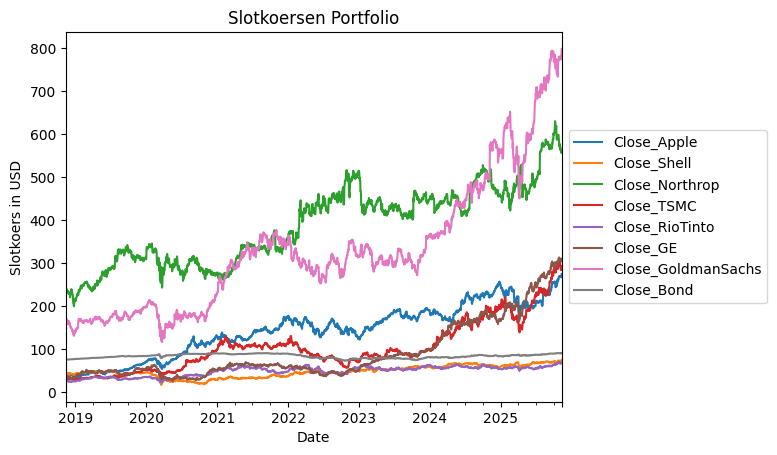

In [29]:
portfolio_plaatje = nans_gevuld.loc[:, ["Close_Apple", "Close_Shell", "Close_Northrop", "Close_TSMC", "Close_RioTinto", "Close_GE", "Close_GoldmanSachs", "Close_Bond"]]
portfolio_plaatje.plot()
plt.ylabel("Slotkoers in USD") # y-as naam geven
ax = plt.subplot(111)
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5)) # zet de legenda buiten de grafiek
plt.title("Slotkoersen Portfolio") # Grafiek een naam geven

Conclusie?

# Grondstoffen en macro-economische indicatoren
https://tradingeconomics.com/commodities

## FRED API Key Setup

To access data from the FRED (Federal Reserve Economic Data) API, you will need an API key. If you don't have one, you can obtain it by registering on the [FRED website](https://fred.stlouisfed.org/docs/api/api_key.html).

Once you have your API key, it's best practice to store it securely in Colab's **Secrets** manager. Click the "🔑" icon on the left panel, add a new secret, and name it `FRED_API_KEY`. Then, you can access it in your notebook as shown below.

In [13]:
! pip install fredapi

In [9]:
# Load the FRED API key from Colab secrets
from google.colab import userdata
from fredapi import Fred

FRED_API_KEY = userdata.get('FRED_API_Key')

# Ensure the API key is loaded and initialize Fred
if FRED_API_KEY is None:
    print("Warning: FRED_API_Key not found in Colab secrets. Please add it.")
else:
    print("FRED API Key loaded successfully.")
    fred = Fred(api_key=FRED_API_KEY)

FRED API Key loaded successfully.


In [30]:
inflatie = fred.get_series('T10YIE', start, end) #inflatie
rente = fred.get_series('FEDFUNDS', start, end) #rente

In [31]:
graan = fred.get_series('PWHEAMTUSDM', start, end) #graan
hout = fred.get_series('WPU08', start, end) #hout
katoen = fred.get_series('PCOTTINDUSDM', start, end) #katoen
koffie = fred.get_series('WPU026301', start, end) #koffiebonen
rubber = fred.get_series('PRUBBUSDM', start, end) #rubber
vlees = fred.get_series('PBEEFUSDM', start, end) #vleesprijs
wol = fred.get_series('PWOOLFUSDM', start, end) #wol
zonnebloem = fred.get_series('PSUNOUSDM', start, end) #zonnebloemolie

gas = fred.get_series('GASREGW', start, end) #gas (US Regular All Formulations Gas Price)
kolen = fred.get_series('WPU058103', start, end) #kolen (Producer Price Index by Commodity: Fuels and Related Products and Power: Other Petroleum and Coal Products, Including Coke Oven Products, Not Elsewhere Classified)
oil = yf.download('CL=F', start, end).tz_localize(None) #olie
uranium = fred.get_series('PURANUSDM', start, end) #uranium

goud = yf.download('GC=F', start, end).tz_localize(None) #goud future
koper = fred.get_series('PCOPPUSDM', start, end) #koperprijs
palladium = yf.download('PA=F', start, end).tz_localize(None) #palladium
staal = fred.get_series('WPU101707', start, end) #staal (Producer Price Index by Commodity: Metals and Metal Products: Cold Rolled Steel Sheet and Strip )
zilver = yf.download('SI=F', start, end).tz_localize(None) #zilver future

#kobalt
#silicium

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [32]:
koffie

,0
2018-11-01,193.600
2018-12-01,193.800
2019-01-01,193.900
2019-02-01,194.500
2019-03-01,195.000
...,...
2025-07-01,338.897
2025-08-01,362.016
2025-09-01,359.903
2025-10-01,361.677


Sowieso toe te voegen aan deze tabellen: is dit een prijs per dag? In welke eenheid? Per m3 of liter of vat of ..

## Alternatieve bron van informatie: de Wereldbank

In [33]:
import pandas_datareader.wb as pdr_wb
gdp_wb = pdr_wb.download(indicator='NY.GDP.PCAP.CD', country=['US', 'CN', 'GB'], start=start.year, end=end.year)
display(gdp_wb)

/tmp/ipykernel_11572/4173106189.py:2: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  gdp_wb = pdr_wb.download(indicator='NY.GDP.PCAP.CD', country=['US', 'CN', 'GB'], start=start.year, end=end.year)


NY.GDP.PCAP.CD
country        year                
China          2025             NaN
               2024    13303.148154
               2023    12951.178240
               2022    12970.605641
               2021    12887.435724
               2020    10627.463799
               2019    10342.900952
               2018    10085.663815
United Kingdom 2025             NaN
               2024    53246.367615
               2023    49944.470212
               2022    47057.043229
               2021    47691.376880
               2020    40812.679466
               2019    43158.741127
               2018    43702.997630
United States  2025             NaN
               2024    84534.040784
               2023    81032.262118
               2022    76657.248884
               2021    70205.050916
               2020    63515.949181
               2019    64746.450678
               2018    62499.874439

This code block fetches GDP per capita (indicator NY.GDP.PCAP.CD) from the World Bank ('wb') for the specified start and end dates, for the United States, China, and Great Britain. The country parameter allows you to specify a list of country codes to retrieve data for. You can find indicator codes on the World Bank's data website if you're looking for different metrics.

In [34]:
inflation_wb = pdr_wb.download(indicator='FP.CPI.TOTL.ZG', country=['US', 'CN', 'GB', 'NL'], start=start.year, end=end.year)
display(inflation_wb)

/tmp/ipykernel_11572/1026096747.py:1: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  inflation_wb = pdr_wb.download(indicator='FP.CPI.TOTL.ZG', country=['US', 'CN', 'GB', 'NL'], start=start.year, end=end.year)


FP.CPI.TOTL.ZG
country        year                
China          2025             NaN
               2024        0.218129
               2023        0.234837
               2022        1.973576
               2021        0.981015
               2020        2.419422
               2019        2.899234
               2018        2.074790
United Kingdom 2025             NaN
               2024        3.271573
               2023        6.793967
               2022        7.922049
               2021        2.518371
               2020        0.989487
               2019        1.738105
               2018        2.292840
Netherlands    2025             NaN
               2024        3.347543
               2023        3.838394
               2022       10.001208
               2021        2.675720
               2020        1.272460
               2019        2.633699
               2018        1.703498
United States  2025             NaN
               2024        2.949525
               2023        4.116338
               2022        8.002800
               2021        4.697859
               2020        1.233584
               2019        1.812210
               2018        2.442583

This code retrieves the 'Inflation, consumer prices (annual %)' from the World Bank for the United States (US), China (CN), Great Britain (GB), and the Netherlands (NL) for the specified period. You can replace these country codes with others or add more as needed.

## Portfolio's

In [35]:
indicatoren = pd.concat([rente, inflatie], axis=1)
indicatoren.columns = ["Rente", "Inflatie"]
indicatoren

,Rente,Inflatie
2018-11-01,2.2,NaN
2018-11-12,NaN,NaN
2018-11-13,NaN,2.02
2018-11-14,NaN,2.00
2018-11-15,NaN,2.00
...,...,...
2025-11-06,NaN,2.28
2025-11-07,NaN,2.28
2025-11-10,NaN,2.29
2025-11-11,NaN,NaN


In [36]:
grondstoffen_1 = pd.concat([graan, koffie, vlees, gas, kolen], axis=1)
grondstoffen_1.columns = ["Graan", "Koffie", "Vlees", "Gas", "Kolen"]
grondstoffen_1

,Graan,Koffie,Vlees,Gas,Kolen
2018-11-01,181.552391,193.600,171.022727,NaN,634.300
2018-11-12,NaN,NaN,NaN,2.686,NaN
2018-11-19,NaN,NaN,NaN,2.611,NaN
2018-11-26,NaN,NaN,NaN,2.539,NaN
2018-12-01,188.535836,193.800,183.190476,NaN,601.200
...,...,...,...,...,...
2025-10-20,NaN,NaN,NaN,3.019,NaN
2025-10-27,NaN,NaN,NaN,3.035,NaN
2025-11-01,169.203288,361.565,325.500000,NaN,870.659
2025-11-03,NaN,NaN,NaN,3.019,NaN


In [37]:
grondstoffen_2 = pd.concat([oil.add_suffix("_Olie"), goud.add_suffix("_Goud"), palladium.add_suffix("_Palladium")], axis = 1)
grondstoffen_2 = grondstoffen_2.loc[:, ["Close_Olie", "Close_Goud", "Close_Palladium"]]
grondstoffen_2.columns = ["Olie", "Goud", "Palladium"]
grondstoffen_2

,Olie,Goud,Palladium
Date,,,
2018-11-12,59.930000,1201.300049,1102.199951
2018-11-13,55.689999,1199.199951,1108.699951
2018-11-14,56.250000,1207.900024,1126.800049
2018-11-15,56.459999,1212.800049,1154.000000
2018-11-16,56.459999,1220.800049,1171.199951
...,...,...,...
2025-11-05,59.599998,3980.300049,1442.400024
2025-11-06,59.430000,3979.899902,1388.099976
2025-11-07,59.750000,3999.399902,1397.300049


In [38]:
grondstoffen_compleet = pd.concat([grondstoffen_1, grondstoffen_2], axis=1)
grondstoffen_compleet

,Graan,Koffie,Vlees,Gas,Kolen,Olie,Goud,Palladium
2018-11-01,181.552391,193.6,171.022727,NaN,634.3,NaN,NaN,NaN
2018-11-12,NaN,NaN,NaN,2.686,NaN,59.930000,1201.300049,1102.199951
2018-11-13,NaN,NaN,NaN,NaN,NaN,55.689999,1199.199951,1108.699951
2018-11-14,NaN,NaN,NaN,NaN,NaN,56.250000,1207.900024,1126.800049
2018-11-15,NaN,NaN,NaN,NaN,NaN,56.459999,1212.800049,1154.000000
...,...,...,...,...,...,...,...,...
2025-11-05,NaN,NaN,NaN,NaN,NaN,59.599998,3980.300049,1442.400024
2025-11-06,NaN,NaN,NaN,NaN,NaN,59.430000,3979.899902,1388.099976
2025-11-07,NaN,NaN,NaN,NaN,NaN,59.750000,3999.399902,1397.300049
2025-11-10,NaN,NaN,NaN,3.056,NaN,60.130001,4111.799805,1443.099976


## Schonen van de data
We zien dat lang niet alle dagen gevuld zijn. Hoe komt dat?<br>
- sommige indicatoren hebben 1x per maand een waarde (prijs)<br>
- sommige indicatoren hebben 1x per week een waarde<br>
- sommige indicatoren hebben 1x per dag een waarde<br>

Hoe lossen we dit op?<br>
Een mogelijkheid is om alle week- en maanddata op te vullen (= forward fillen en/of backward fillen) totdat alle dagen gevuld zijn:

In [44]:
grondstoffen_compleet_gevuld = grondstoffen_compleet.ffill().bfill()
grondstoffen_compleet_gevuld

,Graan,Koffie,Vlees,Gas,Kolen,Olie,Goud,Palladium
2018-11-01,181.552391,193.600,171.022727,2.686,634.300,59.930000,1201.300049,1102.199951
2018-11-12,181.552391,193.600,171.022727,2.686,634.300,59.930000,1201.300049,1102.199951
2018-11-13,181.552391,193.600,171.022727,2.686,634.300,55.689999,1199.199951,1108.699951
2018-11-14,181.552391,193.600,171.022727,2.686,634.300,56.250000,1207.900024,1126.800049
2018-11-15,181.552391,193.600,171.022727,2.686,634.300,56.459999,1212.800049,1154.000000
...,...,...,...,...,...,...,...,...
2025-11-05,169.203288,361.565,325.500000,3.019,870.659,59.599998,3980.300049,1442.400024
2025-11-06,169.203288,361.565,325.500000,3.019,870.659,59.430000,3979.899902,1388.099976
2025-11-07,169.203288,361.565,325.500000,3.019,870.659,59.750000,3999.399902,1397.300049
2025-11-10,169.203288,361.565,325.500000,3.056,870.659,60.130001,4111.799805,1443.099976


We zijn nu bijna waar we wezen willen: alle rijen en kolommen gevuld.<br>
Laatste schoonmaakactie: het verwijderen / filteren van alle overgebleven NaN's.<p>
Dit doen we door als startdatum een datum te kiezen waarbij voor ALLE indicatoren prijzen per dag aanwezig zijn.
We zoeken eerst deze datum:

In [42]:
grondstoffen_compleet = grondstoffen_compleet_gevuld.loc[grondstoffen_compleet_gevuld.loc[:, "Graan"] > 0, :]
grondstoffen_compleet

,Graan,Koffie,Vlees,Gas,Kolen,Olie,Goud,Palladium
2018-11-01,181.552391,193.600,171.022727,2.686,634.300,59.930000,1201.300049,1102.199951
2018-11-12,181.552391,193.600,171.022727,2.686,634.300,59.930000,1201.300049,1102.199951
2018-11-13,181.552391,193.600,171.022727,2.686,634.300,55.689999,1199.199951,1108.699951
2018-11-14,181.552391,193.600,171.022727,2.686,634.300,56.250000,1207.900024,1126.800049
2018-11-15,181.552391,193.600,171.022727,2.686,634.300,56.459999,1212.800049,1154.000000
...,...,...,...,...,...,...,...,...
2025-11-05,169.203288,361.565,325.500000,3.019,870.659,59.599998,3980.300049,1442.400024
2025-11-06,169.203288,361.565,325.500000,3.019,870.659,59.430000,3979.899902,1388.099976
2025-11-07,169.203288,361.565,325.500000,3.019,870.659,59.750000,3999.399902,1397.300049
2025-11-10,169.203288,361.565,325.500000,3.056,870.659,60.130001,4111.799805,1443.099976


De datum die we zoeken is 1 november 2018. Deze datum kunnen we nu gebruiken als startdatum voor onze portfolio en indicatoren.

## Statistiek

In [45]:
grondstoffen_compleet.describe()

,Graan,Koffie,Vlees,Gas,Kolen,Olie,Goud,Palladium
count,1826.000000,1826.000000,1826.000000,1826.000000,1826.000000,1826.000000,1826.000000,1826.000000
mean,231.961891,234.444958,238.636964,3.083680,717.191933,67.983324,2018.940797,1658.827273
std,71.080826,46.199573,35.504627,0.611644,193.709895,18.012857,593.225512,564.136913
min,146.570486,193.400000,171.022727,1.773000,415.700000,-37.630001,1199.199951,822.799988
25%,174.816743,195.100000,206.875000,2.615000,575.500000,57.222501,1718.925018,1137.325043
50%,208.381685,222.804000,239.952381,3.127500,680.741000,69.225002,1858.599976,1550.300049
75%,278.617601,256.010000,269.181818,3.453000,858.597000,78.605000,2046.999969,2137.975037
max,444.156568,362.016000,325.500000,5.006000,1196.186000,123.699997,4336.399902,2985.399902


## Grafieken
Als voorbeeld gebruiken we de prijs van goud en van palladium:

Text(0.5, 1.0, 'Prijzen per dag per indicator')

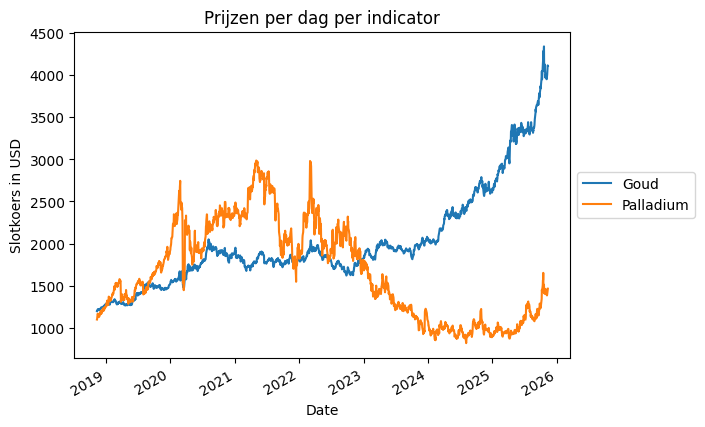

In [46]:
grondstoffen_plaatje = grondstoffen_2.loc[:, ["Goud", "Palladium"]]
grondstoffen_plaatje.plot()
plt.ylabel("Slotkoers in USD") # y-as naam geven
ax = plt.subplot(111)
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5)) # zet de legenda buiten de grafiek
plt.title("Prijzen per dag per indicator") # Grafiek een naam geven

# Hoe kun je de portfolio, de grondstoffen en de macro-economische data samenvoegen?
Via een concat, join, append of een merge.

## Concat

In [48]:
apt = pd.concat([nans_gevuld, indicatoren, grondstoffen_compleet], axis=1)
apt_fill = apt.ffill().bfill()
apt_fill

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple,Rente,Inflatie,Graan,Koffie,Vlees,Gas,Kolen,Olie,Goud,Palladium
2018-11-01,46.070129,44.629486,244.429993,31.536219,26.870062,36.988667,172.680359,75.724152,6371.270020,0.517165,2.20,2.02,181.552391,193.600,171.022727,2.686,634.300,59.930000,1201.300049,1102.199951
2018-11-12,46.070129,44.629486,244.429993,31.536219,26.870062,36.988667,172.680359,75.724152,6371.270020,0.517165,2.20,2.02,181.552391,193.600,171.022727,2.686,634.300,59.930000,1201.300049,1102.199951
2018-11-13,45.609844,43.595592,240.986542,31.825531,26.843315,39.858891,171.842316,75.709160,6359.490234,0.510112,2.20,2.02,181.552391,193.600,171.022727,2.686,634.300,55.689999,1199.199951,1108.699951
2018-11-14,44.321476,44.040752,238.414993,32.199951,26.201387,38.516365,169.696884,75.769142,5738.350098,0.474372,2.20,2.00,181.552391,193.600,171.022727,2.686,634.300,56.250000,1207.900024,1126.800049
2018-11-15,45.415272,44.959473,239.850540,32.778610,26.773775,37.821957,170.744492,75.821571,5648.029785,0.481708,2.20,2.00,181.552391,193.600,171.022727,2.686,634.300,56.459999,1212.800049,1154.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-11-08,267.712616,73.517387,562.033081,284.260071,67.443977,306.472534,774.949280,90.738197,102282.117188,2.284895,3.88,2.28,169.203288,361.565,325.500000,3.019,870.659,59.750000,3999.399902,1397.300049
2025-11-09,267.712616,73.517387,562.033081,284.260071,67.443977,306.472534,774.949280,90.738197,104719.640625,2.367657,3.88,2.28,169.203288,361.565,325.500000,3.019,870.659,59.750000,3999.399902,1397.300049
2025-11-10,268.930359,74.460793,556.468201,292.961487,68.377861,311.130463,785.651978,90.757614,105996.593750,2.526365,3.88,2.29,169.203288,361.565,325.500000,3.056,870.659,60.130001,4111.799805,1443.099976
2025-11-11,274.739563,74.898453,560.184692,288.893585,68.407043,309.913605,798.572021,90.961517,102997.468750,2.391724,3.88,2.29,169.203288,361.565,325.500000,3.056,870.659,61.040001,4106.799805,1467.599976


## Join

In [49]:
nans_gevuld.join(grondstoffen_compleet)

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple,Graan,Koffie,Vlees,Gas,Kolen,Olie,Goud,Palladium
Date,,,,,,,,,,,,,,,,,,
2018-11-12,46.070129,44.629486,244.429993,31.536219,26.870062,36.988667,172.680359,75.724152,6371.270020,0.517165,181.552391,193.600,171.022727,2.686,634.300,59.930000,1201.300049,1102.199951
2018-11-13,45.609844,43.595592,240.986542,31.825531,26.843315,39.858891,171.842316,75.709160,6359.490234,0.510112,181.552391,193.600,171.022727,2.686,634.300,55.689999,1199.199951,1108.699951
2018-11-14,44.321476,44.040752,238.414993,32.199951,26.201387,38.516365,169.696884,75.769142,5738.350098,0.474372,181.552391,193.600,171.022727,2.686,634.300,56.250000,1207.900024,1126.800049
2018-11-15,45.415272,44.959473,239.850540,32.778610,26.773775,37.821957,170.744492,75.821571,5648.029785,0.481708,181.552391,193.600,171.022727,2.686,634.300,56.459999,1212.800049,1154.000000
2018-11-16,45.918285,45.221977,240.105911,31.374531,27.244522,37.127541,169.386826,76.038902,5575.549805,0.471609,181.552391,193.600,171.022727,2.686,634.300,56.459999,1220.800049,1171.199951
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-11-07,267.712616,73.517387,562.033081,284.260071,67.443977,306.472534,774.949280,90.738197,103372.406250,2.314163,169.203288,361.565,325.500000,3.019,870.659,59.750000,3999.399902,1397.300049
2025-11-08,267.712616,73.517387,562.033081,284.260071,67.443977,306.472534,774.949280,90.738197,102282.117188,2.284895,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-11-09,267.712616,73.517387,562.033081,284.260071,67.443977,306.472534,774.949280,90.738197,104719.640625,2.367657,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Ook bij de join geldt: begindatum is niet aangepast, daarnaast is hier de forward-fill nog niet toegepast. En: de join is nu nog niet volledig: de indicatoren ontbreken nog!

## Append
De append voegt de complete grondstoffen-tabel toe aan de portfolio-tabel, maar combineert deze beide tabellen niet.<p>

In pandas versions 1.4.0 and later, the append method for DataFrames has been removed. It's now recommended to use pandas.concat instead.<p>

Voor ons doel dus  niet bruikbaar.

## Merge

In [51]:
apt = pd.merge(nans_gevuld, grondstoffen_compleet, left_index=True, right_index=True)
apt

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple,Graan,Koffie,Vlees,Gas,Kolen,Olie,Goud,Palladium
2018-11-12,46.070129,44.629486,244.429993,31.536219,26.870062,36.988667,172.680359,75.724152,6371.270020,0.517165,181.552391,193.600,171.022727,2.686,634.300,59.930000,1201.300049,1102.199951
2018-11-13,45.609844,43.595592,240.986542,31.825531,26.843315,39.858891,171.842316,75.709160,6359.490234,0.510112,181.552391,193.600,171.022727,2.686,634.300,55.689999,1199.199951,1108.699951
2018-11-14,44.321476,44.040752,238.414993,32.199951,26.201387,38.516365,169.696884,75.769142,5738.350098,0.474372,181.552391,193.600,171.022727,2.686,634.300,56.250000,1207.900024,1126.800049
2018-11-15,45.415272,44.959473,239.850540,32.778610,26.773775,37.821957,170.744492,75.821571,5648.029785,0.481708,181.552391,193.600,171.022727,2.686,634.300,56.459999,1212.800049,1154.000000
2018-11-16,45.918285,45.221977,240.105911,31.374531,27.244522,37.127541,169.386826,76.038902,5575.549805,0.471609,181.552391,193.600,171.022727,2.686,634.300,56.459999,1220.800049,1171.199951
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-11-05,269.377930,72.564255,563.901245,291.344269,67.181313,304.318146,781.601562,90.456612,103891.835938,2.345225,169.203288,361.565,325.500000,3.019,870.659,59.599998,3980.300049,1442.400024
2025-11-06,269.008942,72.184959,565.344360,286.978638,67.385605,304.477753,776.171326,90.767326,101301.289062,2.210848,169.203288,361.565,325.500000,3.019,870.659,59.430000,3979.899902,1388.099976
2025-11-07,267.712616,73.517387,562.033081,284.260071,67.443977,306.472534,774.949280,90.738197,103372.406250,2.314163,169.203288,361.565,325.500000,3.019,870.659,59.750000,3999.399902,1397.300049
2025-11-10,268.930359,74.460793,556.468201,292.961487,68.377861,311.130463,785.651978,90.757614,105996.593750,2.526365,169.203288,361.565,325.500000,3.056,870.659,60.130001,4111.799805,1443.099976


Begindatum niet aangepast ..  en we missen alle weekenddata! Oppassen dus met dat samenvoegen!

In [52]:
apt = pd.merge(nans_gevuld, grondstoffen_compleet, how='outer', left_index=True, right_index=True)
apt

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple,Graan,Koffie,Vlees,Gas,Kolen,Olie,Goud,Palladium
2018-11-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,181.552391,193.600,171.022727,2.686,634.300,59.930000,1201.300049,1102.199951
2018-11-12,46.070129,44.629486,244.429993,31.536219,26.870062,36.988667,172.680359,75.724152,6371.270020,0.517165,181.552391,193.600,171.022727,2.686,634.300,59.930000,1201.300049,1102.199951
2018-11-13,45.609844,43.595592,240.986542,31.825531,26.843315,39.858891,171.842316,75.709160,6359.490234,0.510112,181.552391,193.600,171.022727,2.686,634.300,55.689999,1199.199951,1108.699951
2018-11-14,44.321476,44.040752,238.414993,32.199951,26.201387,38.516365,169.696884,75.769142,5738.350098,0.474372,181.552391,193.600,171.022727,2.686,634.300,56.250000,1207.900024,1126.800049
2018-11-15,45.415272,44.959473,239.850540,32.778610,26.773775,37.821957,170.744492,75.821571,5648.029785,0.481708,181.552391,193.600,171.022727,2.686,634.300,56.459999,1212.800049,1154.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-11-07,267.712616,73.517387,562.033081,284.260071,67.443977,306.472534,774.949280,90.738197,103372.406250,2.314163,169.203288,361.565,325.500000,3.019,870.659,59.750000,3999.399902,1397.300049
2025-11-08,267.712616,73.517387,562.033081,284.260071,67.443977,306.472534,774.949280,90.738197,102282.117188,2.284895,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-11-09,267.712616,73.517387,562.033081,284.260071,67.443977,306.472534,774.949280,90.738197,104719.640625,2.367657,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-11-10,268.930359,74.460793,556.468201,292.961487,68.377861,311.130463,785.651978,90.757614,105996.593750,2.526365,169.203288,361.565,325.500000,3.056,870.659,60.130001,4111.799805,1443.099976


Dit ziet er beter uit ... ,  maar ook hier: forward fill nog niet toegepast en begindatum is nog niet aangepast.<br>

Ergo: als we gaan samenvoegen, moeten we eerst de ontbrekende waarden in de kolommen aanvullen met forward_fill. <br>
Kunnen we maandelijkse / wekelijkse data op dagbasis aanvullen? Ja: zie hierboven.

# Correlatiematrix

<Axes: >

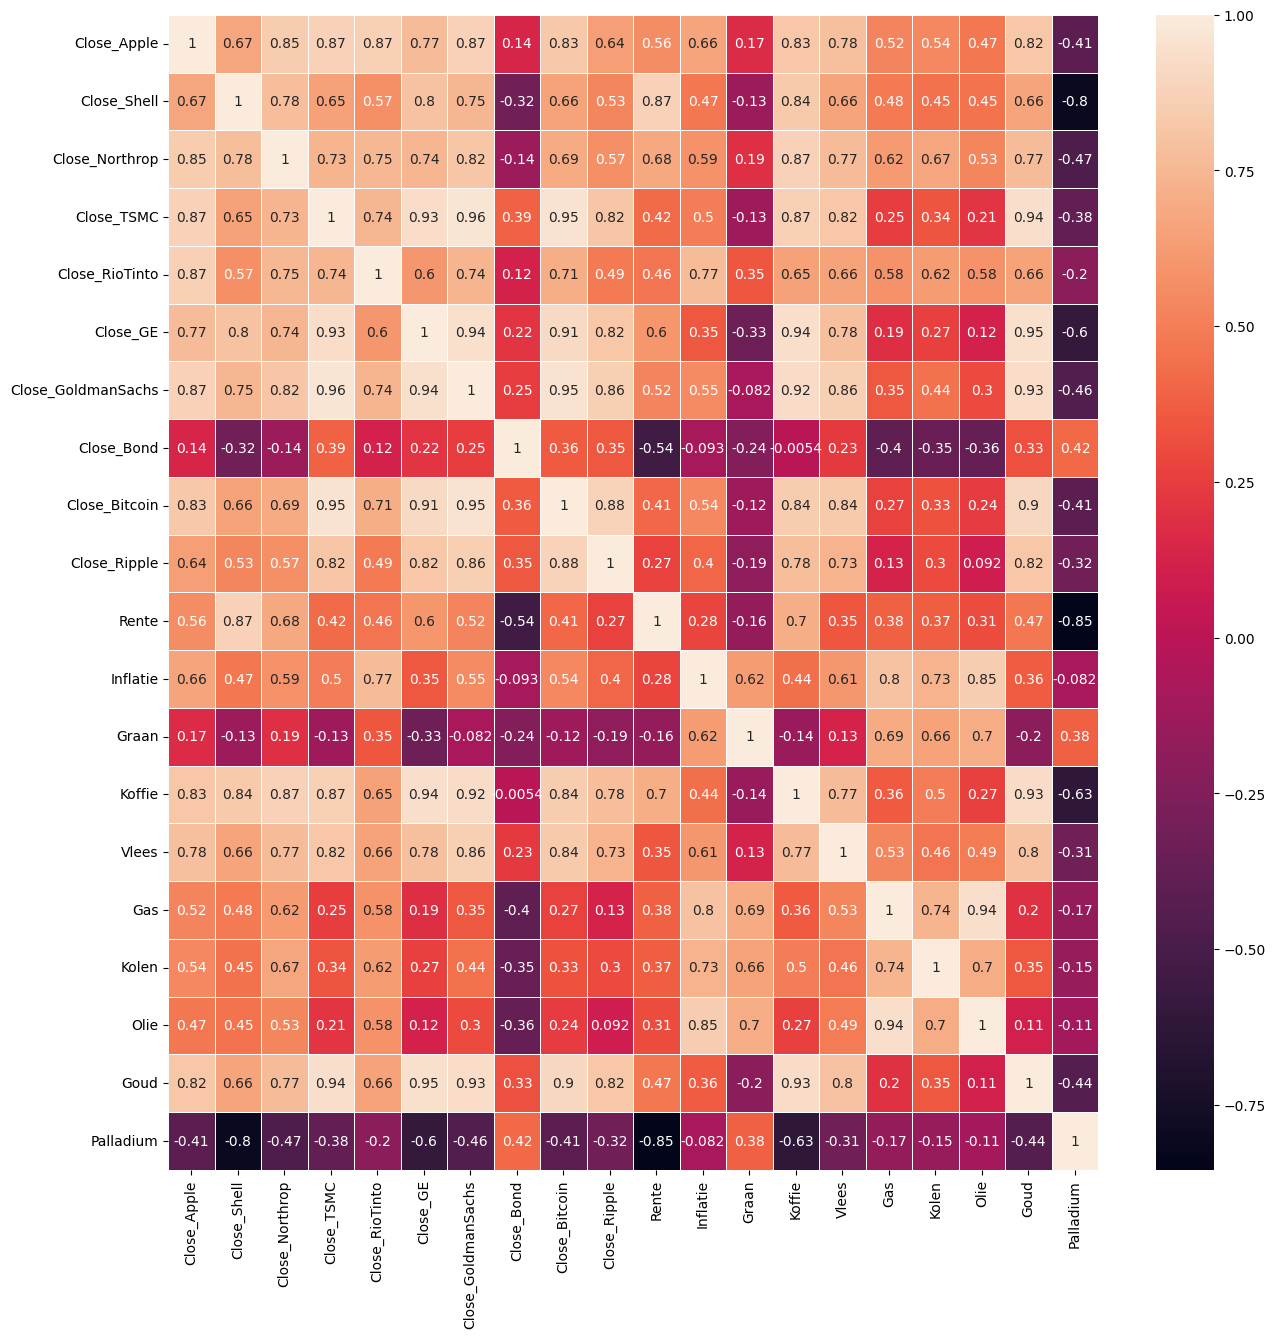

In [53]:
fig, ax = plt.subplots(figsize=(15,15))         # Sample figsize in inches
sns.heatmap(apt_fill.corr(),annot=True, linewidths=.5, ax=ax)

Gebruik de correlatiematrix om te kijken welke verbanden er in julie data zitten - en neem dat mee bij het formuleren van jullie onderzoeksvragen!